In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures as PF
import time

In [ ]:
x = pd.read_csv("https://github.com/koroteevmv/ML_course/raw/main/ML1.2%20multivariate/data/0_x.csv",header=None)
y = pd.read_csv("https://github.com/koroteevmv/ML_course/raw/main/ML1.2%20multivariate/data/0_y.csv",header=None)
x.head()

,0,1,2,3,4
0,0.071841,0.855352,-0.305597,0.028253,1.826895
1,0.139521,-0.423507,0.461059,-0.447400,-0.034988
2,1.626311,-0.257622,-0.697520,1.413219,1.086292
3,-1.183233,-0.826343,0.073047,-0.639690,-0.503273
4,-0.783365,-0.861232,0.951448,-0.117306,0.680597


#1

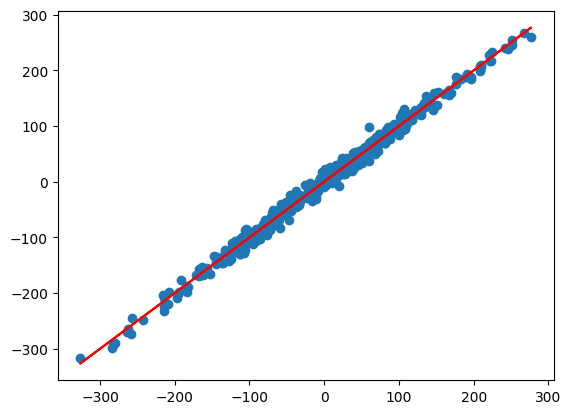

In [ ]:
multiple = LinearRegression()
multiple.fit(x, y)
multiple.score(x, y)
yy = multiple.predict(x)
plt.scatter(yy, y)
plt.plot(yy, yy, c='r')

#2

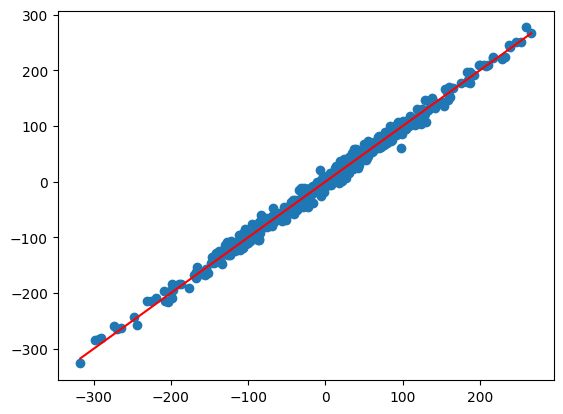

In [ ]:
class Model:


    def __init__(self, n):
        self.b = np.matrix(np.zeros(n + 1)).transpose()
        self.alpha = 0.1

    def predict(self, X):
        #return np.matmul(np.matrix(X),self.b)
        return np.matmul(X,self.b)

    def error(self, X, Y):
        #return sum(((self.predict(X) - Y).values**2) / (2 * len(X)))
        #g = (1/2*X.shape[0]) * (Y - X * self.b).transpose() * (Y - X * self.b)
        return (1/2*X.shape[0]) * (Y - X * self.b).transpose() * (Y - X * self.b)

    def DJ(self,X,Y):
        return -1*(1/X.shape[0]) * X.transpose() * (Y - X * self.b)
#
    def plotGraph(self, X, Y):
        '''
        X0 = np.linspace(X.min(), X.max(), 100)
        Y0 = self.predict(X0)
        plt.figure()
        plt.scatter(X, Y)
        plt.plot(X0, Y0, 'r')
        plt.show()
        '''
        Y_0 = np.array(self.predict(X).flatten())[0]
        if (type(Y) == np.matrix):
          Y0 = np.array(Y.flatten())[0]
        else:
          Y0 = Y
        plt.scatter(Y0, Y_0)
        #plt.plot([Y0.min(),Y0.min()],[Y0.max(),Y0.max()],color='green')
        plt.plot([np.min(Y0),np.max(Y0)],[np.min(Y0),np.max(Y0)],color='red')

    def fit(self, X, Y, accuracy=1e-6, max_steps=5000):

        if (type(X)!=np.matrix):
          X = np.matrix(X)
        if (type(Y)!=np.matrix):
          Y = np.matrix(Y)

        steps, errors = [], []
        step = 0
        old_err = np.inf

        for _ in range(max_steps):
            #обновляем веса
            '''
            dJ0 = sum((self.predict(X) - Y).values) /len(X)
            dJ1 = sum(((self.predict(X) - Y) * X).values) /len(X)
            self.b0 -= self.alpha * dJ0
            self.b1 -= self.alpha * dJ1
            '''
            dJ = self.DJ(X,Y)
            self.b -= self.alpha * dJ
            #вычисляем ошибку
            new_err = self.error(X, Y)

            #print(f'___________\n{step}\ndJ is \n{dJ}\n\nerror is {new_err}\n_________')
            #проверка выхода из цикла
            if abs(new_err - old_err) < accuracy:
              break
            #отладчик
            step += 1
            steps.append(step)
            errors.append(new_err)
            #обновляем ошибку для дальнейшей проверки выхода из цикла
            old_err = new_err


        return steps, errors

#
'''
    def score(self, X, Y):
        y_pred = self.predict(X)
        ss_res = sum((Y - y_pred)**2)
        ss_total = sum((Y - np.mean(Y))**2)
        r2 = 1 - (ss_res / ss_total)
        return r2
'''



'''
xtest = x.iloc[:4,:].values
ytest = y.iloc[:4].values
print(xtest,ytest,sep='\n\n')
print()

m = Model(xtest.shape[0])
print('1')
print(m.predict(xtest))
print('2')
print(m.error(xtest,ytest))
print('3')
print(m.DJ(xtest,ytest))
print('4')
print(m.fit(xtest,ytest))
print('5.1')
print(m.predict(xtest).flatten())
print('5')
print(m.plotGraph(xtest,ytest))
'''
m = Model(x.shape[1])
x_new = np.concatenate((np.repeat(1,x.shape[0]).reshape((x.shape[0],1)),x.values),axis=1)
m.fit(x_new,y)
m.plotGraph(x_new,y)


# 5 Используйте другие метрики качества регрессионной модели в дополнение к коэффициенту детерминации.

In [ ]:
class Model:


    def __init__(self, n):
        self.b = np.matrix(np.zeros(n + 1)).transpose()
        self.alpha = 0.1

    def predict(self, X):
        #return np.matmul(np.matrix(X),self.b)
        return np.matmul(X,self.b)

    def error(self, X, Y):
        #return sum(((self.predict(X) - Y).values**2) / (2 * len(X)))
        #g = (1/2*X.shape[0]) * (Y - X * self.b).transpose() * (Y - X * self.b)
        return (1/2*X.shape[0]) * (Y - X * self.b).transpose() * (Y - X * self.b)

    def DJ(self,X,Y):
        return -1*(1/X.shape[0]) * X.transpose() * (Y - X * self.b)
#
    def plotGraph(self, X, Y):
        '''
        X0 = np.linspace(X.min(), X.max(), 100)
        Y0 = self.predict(X0)
        plt.figure()
        plt.scatter(X, Y)
        plt.plot(X0, Y0, 'r')
        plt.show()
        '''
        Y_0 = np.array(self.predict(X).flatten())[0]
        if (type(Y) == np.matrix):
          Y0 = np.array(Y.flatten())[0]
        else:
          Y0 = Y
        plt.scatter(Y0, Y_0)
        #plt.plot([Y0.min(),Y0.min()],[Y0.max(),Y0.max()],color='green')
        plt.plot([np.min(Y0),np.max(Y0)],[np.min(Y0),np.max(Y0)],color='red')

    def fit(self, X, Y, accuracy=1e-6, max_steps=5000):

        if (type(X)!=np.matrix):
          X = np.matrix(X)
        if (type(Y)!=np.matrix):
          Y = np.matrix(Y)

        steps, errors = [], []
        step = 0
        old_err = np.inf

        for _ in range(max_steps):
            #обновляем веса
            '''
            dJ0 = sum((self.predict(X) - Y).values) /len(X)
            dJ1 = sum(((self.predict(X) - Y) * X).values) /len(X)
            self.b0 -= self.alpha * dJ0
            self.b1 -= self.alpha * dJ1
            '''
            dJ = self.DJ(X,Y)
            self.b -= self.alpha * dJ
            #вычисляем ошибку
            new_err = self.error(X, Y)

            #print(f'___________\n{step}\ndJ is \n{dJ}\n\nerror is {new_err}\n_________')
            #проверка выхода из цикла
            if abs(new_err - old_err) < accuracy:
              break
            #отладчик
            step += 1
            steps.append(step)
            errors.append(new_err)
            #обновляем ошибку для дальнейшей проверки выхода из цикла
            old_err = new_err


        return steps, errors
    def MSE(self,X,Y):
        Y_pred = self.predict(X)
        MSE = (1/Y_pred.shape[0]) * np.sum((Y_pred - Y)**2)
        return MSE

    def RMSE(self,X,Y):
      return np.sqrt(self.MSE(X,Y))

    def MAE(self,X,Y):
      Y_pred = self.predict(X)
      MAE = (1/Y_pred.shape[0]) * np.sum(abs(Y_pred - Y))
      return MAE

    def MAPE(self,X,Y):
      Y_pred = self.predict(X)
      MAPE = (1/Y_pred.shape[0]) * np.sum(abs(Y_pred - Y)/Y)*100
      return MAPE
#

    def score(self, X, Y):
        y_pred = self.predict(X)
        ss_res = np.sum((Y - y_pred)**2)
        ss_total = np.sum((Y - np.mean(Y))**2)
        r2 = 1 - (ss_res / ss_total)
        return r2

m = Model(x.shape[1])
x_new = np.concatenate((np.repeat(1,x.shape[0]).reshape((x.shape[0],1)),x.values),axis=1)

m.fit(x_new,y)

print(m.MSE(x_new,y),m.RMSE(x_new,y),m.MAE(x_new,y),m.MAPE(x_new,y),m.score(x_new,y),sep='\n')

0    93.49229
dtype: float64
0    9.669141
dtype: float64
0    7.780684
dtype: float64
0    5.087759
dtype: float64
0    0.99222
dtype: float64


/usr/local/lib/python3.10/dist-packages/numpy/core/fromnumeric.py:86: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


# 6 Замерьте время обучения полиномиальных моделей с разной степенью полинома. Сделайте вывод.

In [1]:
x_new = np.concatenate((np.repeat(1,x.shape[0]).reshape((x.shape[0],1)),x.values),axis=1)
PFmodel = PF(1)
Lmodel = LinearRegression()
features = PFmodel.fit_transform(x)
Lmodel.fit(features,y)
Lmodel.predict(features)
plt.scatter(y,Lmodel.predict(x_new))

NameError: name 'np' is not defined

In [ ]:
x1 = pd.read_csv("https://github.com/koroteevmv/ML_course/raw/main/ML1.2%20multivariate/data/10_x.csv",header=None)
y1 = pd.read_csv("https://github.com/koroteevmv/ML_course/raw/main/ML1.2%20multivariate/data/10_y.csv",header=None)
x1.head()

,0,1,2,3,4
0,-1.590103,-1.023308,0.139891,1.351945,0.998685
1,-0.235861,-1.108386,2.553156,-1.911015,0.859437
2,0.037993,-2.136154,0.903113,1.095856,1.024503
3,-1.170747,-1.549586,1.827438,-0.519883,1.216156
4,1.060144,-1.086193,-1.251762,-0.571059,-0.107315


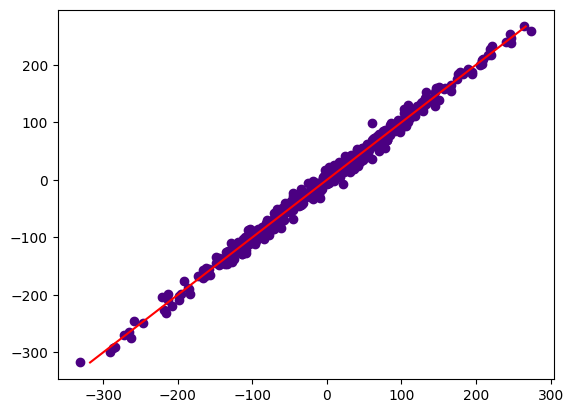

0.9926004162659386

In [ ]:
class PolyModel:

  def __init__(self):
    self.Lmodel = 0
    self.PFmodel = 0
    self.features = 0

  def fit(self,X,Y,degree = 1):
    TIME_START = time.time()
    self.PFmodel = PF(degree)
    self.Lmodel = LinearRegression()
    self.features = self.PFmodel.fit_transform(X)
    self.Lmodel.fit(self.features,Y)
    TIME_FINISH = time.time()
    return TIME_FINISH - TIME_START

  def PLOT(self,X,Y):
    #features = self.PFmodel.transform(X)
    plt.scatter(self.Lmodel.predict(self.features),Y,color='indigo')
    plt.plot([np.min(Y),np.max(Y)],[np.min(Y),np.max(Y)],color='red')
    plt.show()
  def score(self,X,Y):
    return self.Lmodel.score(self.features,Y)
    #plt.scatter(y,Lmodel.predict(x_new))


PM = PolyModel()
PM.fit(x,y,2)
PM.PLOT(x,y)
PM.score(x,y)

In [ ]:
A = time.time()
time.sleep(2)
time.time() - A

2.002162218093872

In [ ]:
for i in range(49):
  print(f'for x_{i} and y_{i}')
  xn = pd.read_csv(f"https://github.com/koroteevmv/ML_course/raw/main/ML1.2%20multivariate/data/{i}_x.csv",header=None)
  yn = pd.read_csv(f"https://github.com/koroteevmv/ML_course/raw/main/ML1.2%20multivariate/data/{i}_y.csv",header=None)
  for j in range(1,6):
    PM = PolyModel()
    print(f'time for {j}-th degree is {PM.fit(xn,yn,j)} seconds with a {PM.score(xn,yn)} score')
    PM.PLOT(xn,yn)
  print("___________\n\n\n\n___________")

Output hidden; open in https://colab.research.google.com to view.